Download the dataset

In [ ]:
!wget --no-check-certificate -O kvasir-capsule-labeled-images.zip https://datasets.simula.no/downloads/kvasir-capsule/kvasir-capsule-labeled-images.zip

--2026-10-15 02:57:09--  https://datasets.simula.no/downloads/kvasir-capsule/kvasir-capsule-labeled-images.zip
Resolving datasets.simula.no (datasets.simula.no)... 128.39.36.14
Connecting to datasets.simula.no (datasets.simula.no)|128.39.36.14|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 546316156 (521M) [application/zip]
Saving to: ‘kvasir-capsule-labeled-images.zip’

kvasir-capsule-labe 100%[===================>] 521.01M  6.46MB/s    in 70s     

2026-10-15 02:58:21 (7.40 MB/s) - ‘kvasir-capsule-labeled-images.zip’ saved [546316156/546316156]



Unzip the dataset

In [ ]:
!unzip -q -o kvasir-capsule-labeled-images.zip -d kvasir && while [ -n "$(find kvasir -type f \( -name '*.zip' -o -name '*.gz' -o -name '*.tgz' \) | head -1)" ]; do find kvasir -type f \( -name '*.zip' -o -name '*.gz' -o -name '*.tgz' \) -exec sh -c 'f="$1"; d=$(dirname "$f"); case "$f" in *.tar.gz|*.tgz) tar -xzf "$f" -C "$d" && rm -f "$f";; *.gz) gunzip -f "$f";; *.zip) unzip -q -o "$f" -d "$d" && rm -f "$f";; esac' _ {} \; ; done

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

In [ ]:

# ============================================================
# 1. SETTINGS
# ============================================================

# CHANGE THIS TO YOUR DATASET LOCATION
DATA_DIR = "kvasir/labelled_images"

# Resize every image
IMG_SIZE = 64

TEST_SIZE = 0.20
RANDOM_STATE = 42
MAX_IMAGES_PER_CLASS = None

In [ ]:


# ============================================================
# 2. FIND CLASS NAMES
# ============================================================

class_names = sorted([
    folder
    for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

num_classes = len(class_names)

print("\n===========================================")
print("Kvasir-Capsule Dataset")
print("===========================================")

print(f"Number of classes: {num_classes}")

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

if num_classes != 14:
    print(
        f"\nWARNING: Expected 14 classes, "
        f"but found {num_classes}."
    )



Kvasir-Capsule Dataset
Number of classes: 14
0: Ampulla of vater
1: Angiectasia
2: Blood - fresh
3: Blood - hematin
4: Erosion
5: Erythema
6: Foreign body
7: Ileocecal valve
8: Lymphangiectasia
9: Normal clean mucosa
10: Polyp
11: Pylorus
12: Reduced mucosal view
13: Ulcer


In [ ]:
# ============================================================
# 3. LOAD IMAGES
# ============================================================

X = []
y = []

valid_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

print("\nLoading images...")

for class_index, class_name in enumerate(class_names):

    class_folder = os.path.join(
        DATA_DIR,
        class_name
    )

    image_files = [
        file
        for file in os.listdir(class_folder)
        if file.lower().endswith(valid_extensions)
    ]

    # Optional limit
    if MAX_IMAGES_PER_CLASS is not None:
        image_files = image_files[:MAX_IMAGES_PER_CLASS]

    print(
        f"{class_name}: "
        f"{len(image_files)} images"
    )

    for filename in tqdm(
        image_files,
        desc=class_name
    ):

        image_path = os.path.join(
            class_folder,
            filename
        )

        try:

            # Open image
            image = Image.open(
                image_path
            ).convert("RGB")

            # Resize
            image = image.resize(
                (IMG_SIZE, IMG_SIZE)
            )

            # Convert to numpy
            image = np.array(
                image,
                dtype=np.float32
            )

            # Normalize pixel values
            image = image / 255.0

            # Flatten:
            # 64 x 64 x 3 -> 12,288 features
            image = image.flatten() #converting the every images into one long vector containing 12,228 pixel features

            X.append(image)

            y.append(class_index)

        except Exception as e:

            print(
                f"Could not load "
                f"{image_path}: {e}"
            )


X = np.array(X, dtype=np.float32) #X shape ≈ (47240, 12288)
y = np.array(y)  #y shape ≈ (47240,)


print("\n===========================================")
print("Feature Matrix")
print("===========================================")

print("Total images:", X.shape[0])
print("Features per image:", X.shape[1])
print("Number of classes:", num_classes)





Loading images...
Ampulla of vater: 10 images


Ampulla of vater: 100%|██████████| 10/10 [00:00<00:00, 161.11it/s]


Angiectasia: 866 images


Angiectasia: 100%|██████████| 866/866 [00:01<00:00, 652.91it/s]


Blood - fresh: 446 images


Blood - fresh: 100%|██████████| 446/446 [00:00<00:00, 640.57it/s]


... (19 outputs left out)

Reduced mucosal view: 100%|██████████| 2906/2906 [00:05<00:00, 574.46it/s]


Ulcer: 854 images


Ulcer: 100%|██████████| 854/854 [00:01<00:00, 613.14it/s]



Feature Matrix
Total images: 47238
Features per image: 12288
Number of classes: 14


In [ ]:
# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=TEST_SIZE,

    stratify=y, #Stratification tries to preserve the original class proportions in both the training and test sets

    random_state=RANDOM_STATE
)

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


# Free original X to save memory
del X




Training samples: 37790
Testing samples : 9448


In [ ]:
# ============================================================
# 5. STANDARDIZE FEATURES
# ============================================================

print("\nStandardizing features...")

scaler = StandardScaler()  #makes the features comparable by centering them and scaling them according to the training data

X_train = scaler.fit_transform(
    X_train
)

X_test = scaler.transform(
    X_test
)


Standardizing features...


In [ ]:
# ============================================================
# 6. LOGISTIC REGRESSION
# ============================================================

print("\nTraining Logistic Regression...")

start_time = time.time()

model = LogisticRegression(

    # Enough iterations for convergence
    max_iter=20,

    # Useful for imbalanced classes, why?
    class_weight="balanced", #this is for rare class

    solver="lbfgs", #numerical optimization algorithm to find the coefficients.

    random_state=RANDOM_STATE
)

model.fit(
    X_train,
    y_train
)

training_time = (
    time.time() - start_time
)

print(
    f"Training completed in "
    f"{training_time:.2f} seconds."
)

In [ ]:
# ============================================================
# 7. PREDICTIONS
# ============================================================

y_pred = model.predict(
    X_test
)

# IMPORTANT FOR ROC / AUC:
# We need probability scores, not only predicted labels.
y_prob = model.predict_proba(
    X_test
)

Check on sample on how the prediction looks like

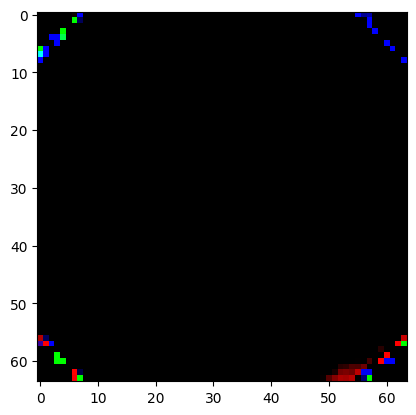

(np.int64(6),
 array([7.46504934e-06, 4.70871023e-13, 5.38069452e-02, 1.76371074e-04,
        1.63498548e-16, 1.25299198e-30, 7.41065600e-01, 2.04721643e-01,
        2.28917010e-09, 5.33781098e-23, 2.21813215e-04, 1.59567669e-07,
        9.32340642e-18, 5.37808935e-14]))

In [ ]:
plt.imshow(X_test[0].reshape(IMG_SIZE, IMG_SIZE, 3))
plt.show()

#Angiectasia
y_pred[0], y_prob[0]

In [ ]:
# ============================================================
# 8. STANDARD CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

macro_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)


print("\n===========================================")
print("LOGISTIC REGRESSION RESULTS")
print("===========================================")

print(
    f"Accuracy          : "
    f"{accuracy:.4f}"
)

print(
    f"Balanced Accuracy : "
    f"{balanced_accuracy:.4f}"
)

print(
    f"Macro Precision   : "
    f"{macro_precision:.4f}"
)

print(
    f"Macro Recall      : "
    f"{macro_recall:.4f}"
)

print(
    f"Macro F1          : "
    f"{macro_f1:.4f}"
)

print(
    f"Weighted F1       : "
    f"{weighted_f1:.4f}"
)



LOGISTIC REGRESSION RESULTS
Accuracy          : 0.3465
Balanced Accuracy : 0.6426
Macro Precision   : 0.2284
Macro Recall      : 0.6426
Macro F1          : 0.2570
Weighted F1       : 0.3811


In [ ]:
# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\n===========================================")
print("CLASSIFICATION REPORT")
print("===========================================")

print(
    classification_report(

        y_test,
        y_pred,

        target_names=class_names,

        digits=4,

        zero_division=0
    )
)



CLASSIFICATION REPORT
                      precision    recall  f1-score   support

    Ampulla of vater     0.0147    0.5000    0.0286         2
         Angiectasia     0.1854    0.7168    0.2945       173
       Blood - fresh     0.2500    0.7865    0.3794        89
     Blood - hematin     0.0105    0.5000    0.0206         2
             Erosion     0.0877    0.5347    0.1506       101
            Erythema     0.0249    0.8125    0.0482        32
        Foreign body     0.1748    0.6258    0.2732       155
     Ileocecal valve     0.4553    0.5656    0.5045       838
    Lymphangiectasia     0.0970    0.6218    0.1678       119
 Normal clean mucosa     0.9736    0.2308    0.3731      6868
               Polyp     0.1019    1.0000    0.1849        11
             Pylorus     0.2565    0.6765    0.3720       306
Reduced mucosal view     0.3587    0.7470    0.4846       581
               Ulcer     0.2064    0.6784    0.3165       171

            accuracy                         

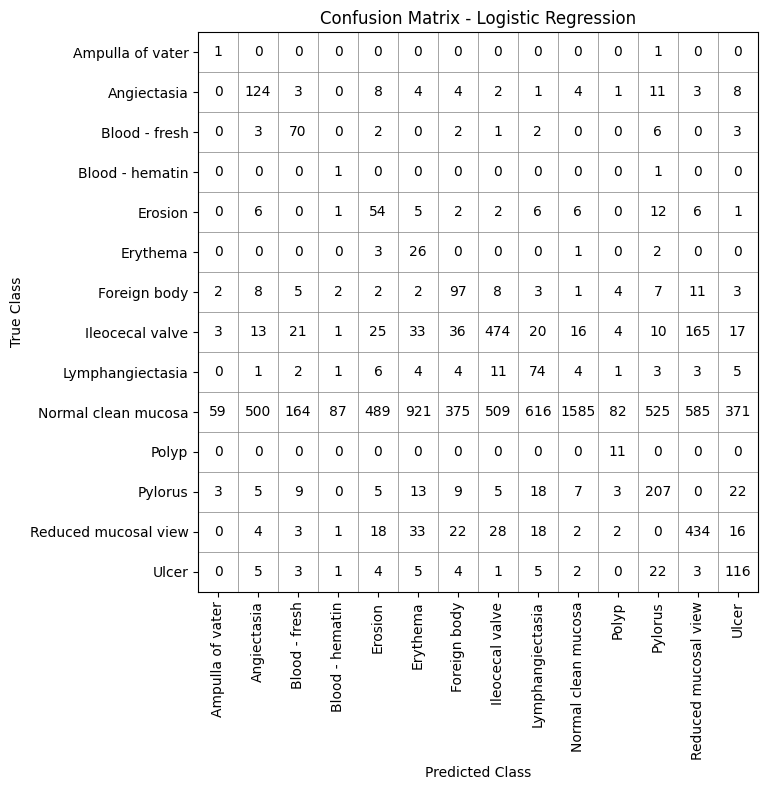

In [ ]:
# confusion matrix without the color (just numbers)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib.colors import ListedColormap
import numpy as np
import matplotlib.pyplot as plt

# Define the confusion matrix 'cm' which was missing
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    ax=ax,
    cmap=ListedColormap(["white"]),
    colorbar=False,
    xticks_rotation=90,
    values_format="d"
)

# make the numbers visible
for text in disp.text_.ravel():
    text.set_color("black")
    text.set_fontsize(10)

# draw cell borders so it looks like a table
ax.set_xticks(np.arange(-0.5, num_classes, 1), minor=True)
ax.set_yticks(np.arange(-0.5, num_classes, 1), minor=True)
ax.grid(which="minor", color="gray", linewidth=0.5)
ax.tick_params(which="minor", length=0)

ax.set_title("Confusion Matrix - Logistic Regression")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

plt.tight_layout()
plt.savefig("confusion_matrix_logistic_regression.png", dpi=300, bbox_inches="tight")
plt.show()

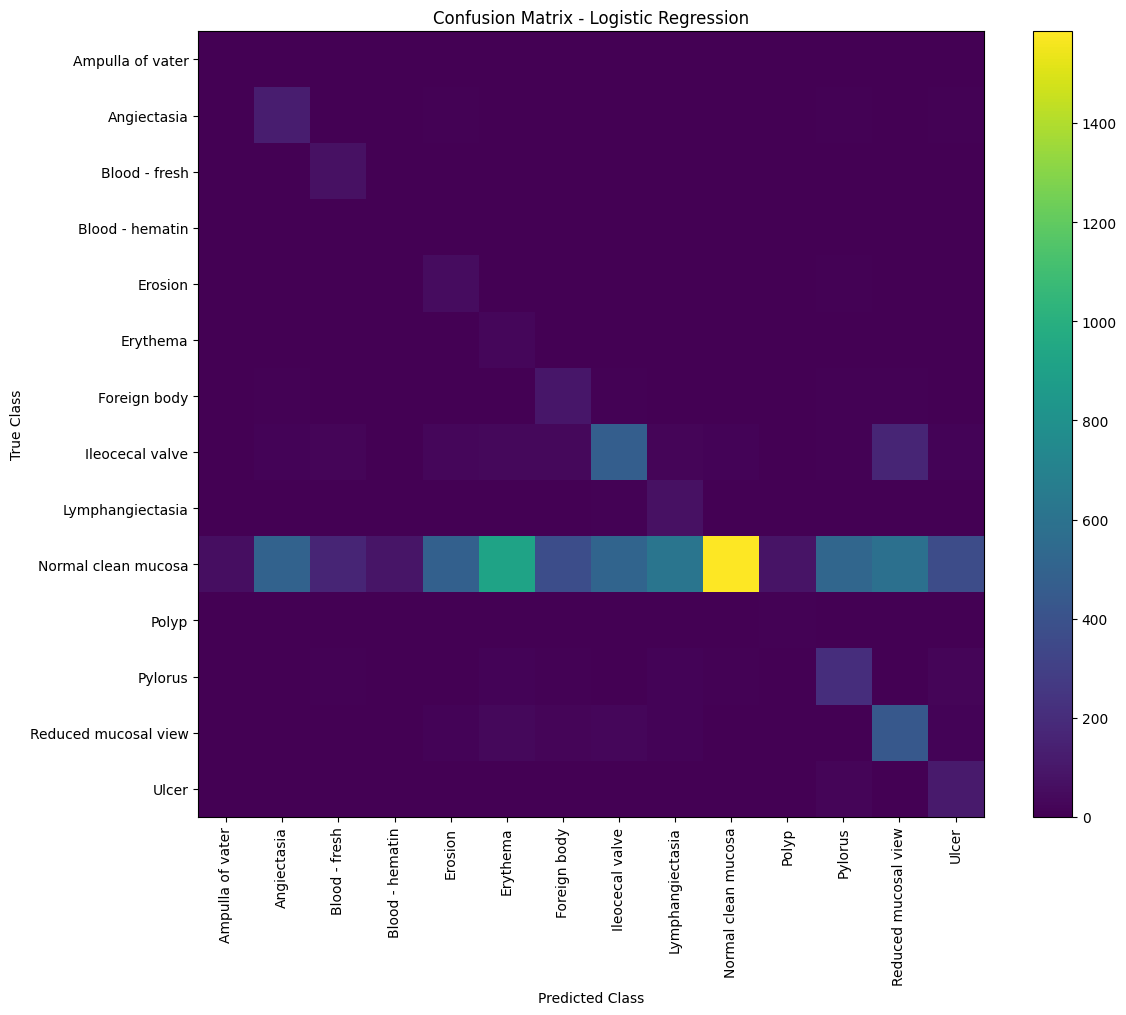

In [ ]:
# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.colorbar()

tick_marks = np.arange(
    num_classes
)

plt.xticks(
    tick_marks,
    class_names,
    rotation=90
)

plt.yticks(
    tick_marks,
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

plt.savefig(
    "confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




In [ ]:
# ============================================================
# 11. PREPARE LABELS FOR ROC
# ============================================================

# Example:
#
# Original:
# Polyp = 5
#
# Binarized:
# [0,0,0,0,0,1,0,...]
#
# This allows one-vs-rest ROC evaluation.

y_test_bin = label_binarize(

    y_test,

    classes=np.arange(
        num_classes
    )
)



In [ ]:

# ============================================================
# 12. AUC FOR EACH CLASS
# ============================================================

fpr = {}
tpr = {}
roc_auc = {}


print("\n===========================================")
print("PER-CLASS ROC-AUC")
print("===========================================")

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(

        y_test_bin[:, i],

        y_prob[:, i]
    )

    roc_auc[i] = auc(

        fpr[i],

        tpr[i]
    )

    print(
        f"{class_names[i]:30s}"
        f" AUC = {roc_auc[i]:.4f}"
    )





PER-CLASS ROC-AUC
Ampulla of vater               AUC = 0.8706
Angiectasia                    AUC = 0.8912
Blood - fresh                  AUC = 0.9489
Blood - hematin                AUC = 0.9830
Erosion                        AUC = 0.8483
Erythema                       AUC = 0.9548
Foreign body                   AUC = 0.8950
Ileocecal valve                AUC = 0.8885
Lymphangiectasia               AUC = 0.8671
Normal clean mucosa            AUC = 0.8214
Polyp                          AUC = 1.0000
Pylorus                        AUC = 0.9220
Reduced mucosal view           AUC = 0.9264
Ulcer                          AUC = 0.9156


In [ ]:
# ============================================================
# 13. MACRO, MICRO AND WEIGHTED AUC
# ============================================================

macro_auc = roc_auc_score(

    y_test_bin,

    y_prob,

    average="macro",

    multi_class="ovr"
)


weighted_auc = roc_auc_score(

    y_test_bin,

    y_prob,

    average="weighted",

    multi_class="ovr"
)


micro_auc = roc_auc_score(

    y_test_bin,

    y_prob,

    average="micro",

    multi_class="ovr"
)


print("\n===========================================")
print("OVERALL ROC-AUC")
print("===========================================")

print(
    f"Macro ROC-AUC    : "
    f"{macro_auc:.4f}"
)

print(
    f"Weighted ROC-AUC : "
    f"{weighted_auc:.4f}"
)

print(
    f"Micro ROC-AUC    : "
    f"{micro_auc:.4f}"
)





OVERALL ROC-AUC
Macro ROC-AUC    : 0.9095
Weighted ROC-AUC : 0.8440
Micro ROC-AUC    : 0.7524


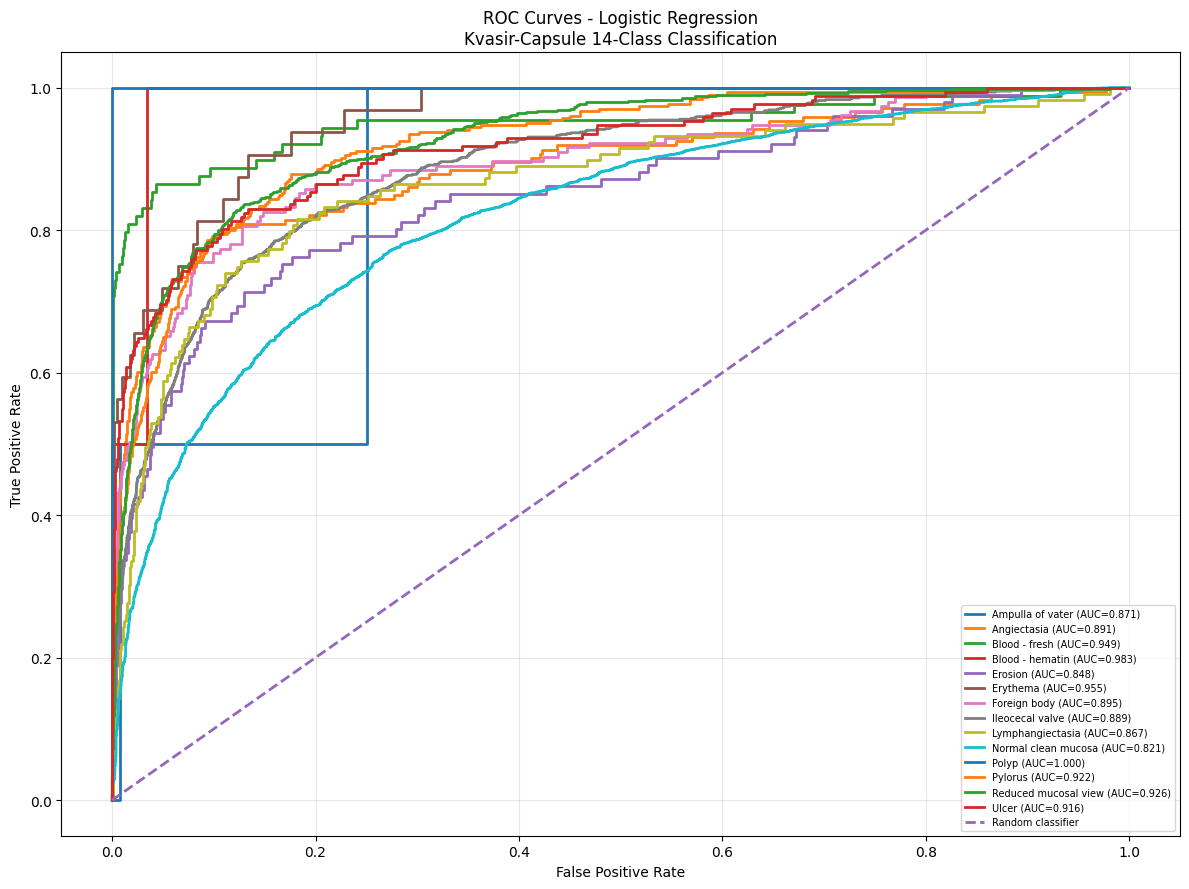

In [ ]:
# ============================================================
# 14. PLOT ALL 14 ROC CURVES
# ============================================================

plt.figure(
    figsize=(12, 9)
)

for i in range(num_classes):

    plt.plot(

        fpr[i],

        tpr[i],

        linewidth=2,

        label=(
            f"{class_names[i]} "
            f"(AUC={roc_auc[i]:.3f})"
        )
    )


# Random classifier
plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=2,

    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curves - Logistic Regression\n"
    "Kvasir-Capsule 14-Class Classification"
)

plt.legend(

    loc="lower right",

    fontsize=7
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    "roc_all_classes_logistic_regression.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()




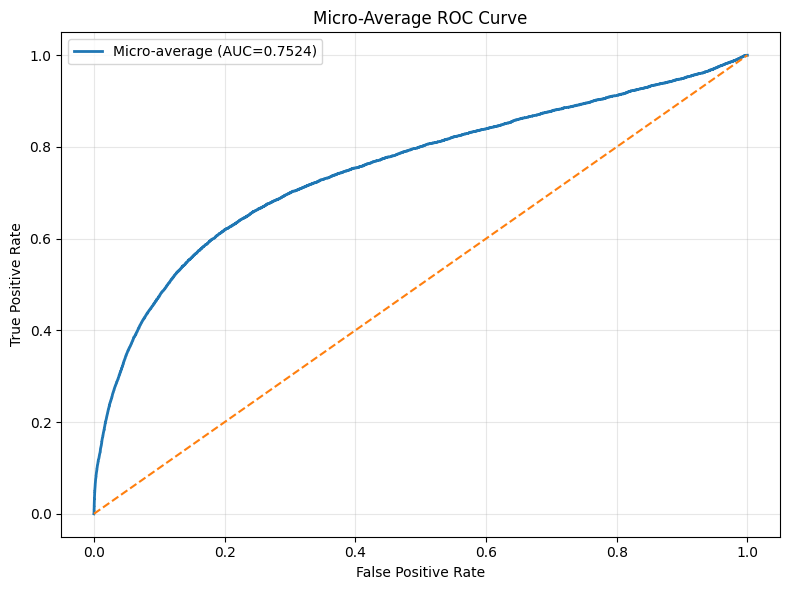

In [ ]:
# ============================================================
# 15. MICRO-AVERAGE ROC CURVE
# ============================================================

fpr_micro, tpr_micro, _ = roc_curve(

    y_test_bin.ravel(),

    y_prob.ravel()
)

micro_curve_auc = auc(

    fpr_micro,

    tpr_micro
)


plt.figure(
    figsize=(8, 6)
)

plt.plot(

    fpr_micro,

    tpr_micro,

    linewidth=2,

    label=(
        f"Micro-average "
        f"(AUC={micro_curve_auc:.4f})"
    )
)

plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Micro-Average ROC Curve"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    "roc_micro_average.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()




In [ ]:
# ============================================================
# 16. CREATE AUC TABLE
# ============================================================

auc_results = []

for i in range(num_classes):

    auc_results.append({

        "Class":
            class_names[i],

        "ROC-AUC":
            roc_auc[i]
    })


auc_df = pd.DataFrame(
    auc_results
)


print("\n===========================================")
print("AUC BY CLASS")
print("===========================================")

print(
    auc_df
    .round(4)
    .to_string(index=False)
)





AUC BY CLASS
               Class  ROC-AUC
    Ampulla of vater   0.8706
         Angiectasia   0.8912
       Blood - fresh   0.9489
     Blood - hematin   0.9830
             Erosion   0.8483
            Erythema   0.9548
        Foreign body   0.8950
     Ileocecal valve   0.8885
    Lymphangiectasia   0.8671
 Normal clean mucosa   0.8214
               Polyp   1.0000
             Pylorus   0.9220
Reduced mucosal view   0.9264
               Ulcer   0.9156


In [ ]:
# ============================================================
# 17. SAVE AUC RESULTS
# ============================================================

auc_df.to_csv(

    "logistic_regression_auc_by_class.csv",

    index=False
)




In [ ]:
# ============================================================
# 18. SAVE OVERALL RESULTS
# ============================================================

overall_results = pd.DataFrame({

    "Metric": [

        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Macro ROC-AUC",
        "Weighted ROC-AUC",
        "Micro ROC-AUC"

    ],

    "Value": [

        accuracy,
        balanced_accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_f1,
        macro_auc,
        weighted_auc,
        micro_auc

    ]
})


overall_results.to_csv(

    "logistic_regression_overall_results.csv",

    index=False
)


print("\n===========================================")
print("FINISHED")
print("===========================================")

print(
    "\nSaved:"
)

print(
    "1. confusion_matrix_logistic_regression.png"
)

print(
    "2. roc_all_classes_logistic_regression.png"
)

print(
    "3. roc_micro_average.png"
)

print(
    "4. logistic_regression_auc_by_class.csv"
)

print(
    "5. logistic_regression_overall_results.csv"
)


FINISHED

Saved:
1. confusion_matrix_logistic_regression.png
2. roc_all_classes_logistic_regression.png
3. roc_micro_average.png
4. logistic_regression_auc_by_class.csv
5. logistic_regression_overall_results.csv


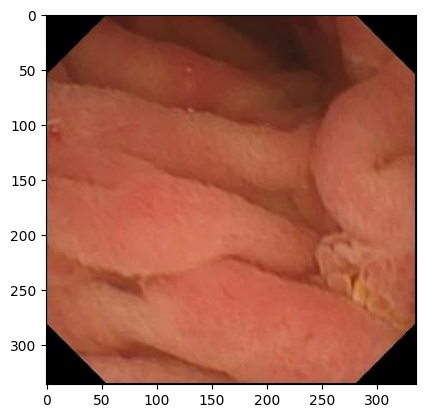

In [ ]:
import matplotlib.pyplot as plt

img = plt.imread('/content/kvasir/labelled_images/Ampulla of vater/eb0203196e284797_1157.jpg')
plt.imshow(img)
plt.show()

In [ ]:
X_train[0]

array([ 0.        ,  0.        ,  0.        , ..., -0.00727508,
       -0.00727508, -0.02153373], dtype=float32)